# Strong-scattering microsphere slab — opaque, diffusive regime
A plane wave on a slab of randomly packed dielectric microspheres -> volumetric
speckle, pushed all the way into the *opaque, diffusive* regime of the experiment
it descends from — Vellekoop & Mosk, "Focusing coherent light through opaque
strongly scattering media", Opt. Lett. 32, 2309 (2007). That paper
used rutile TiO2 pigment (n ≈ 2.7), 10.1 μm thick, transport mean free path
ℓ* ≈ 0.55 μm -> L/ℓ* ≈ 18, so light inside it scatters hundreds of times. Here we
use rutile-grade index contrast, a thick densely-packed slab, and a domain large
enough that the transmitted speckle is measured in the far field.

The grid is ~77 Mvoxel without the absorbing boundaries.

Size: 176.9 Mvoxel including boundaries, 3.96 GB of memory (service estimate).

Comparison observables (compare with Fig. 3a of the paper)
----------------------------------------------------------
  * **Speckle intensity contrast** C = std(I)/mean(I) on the transmitted plane.
    Fully developed (Rayleigh) speckle -> C = 1; their Fig. 3a is fully developed.
  * **Far-field speckle grain size** from the transverse intensity autocorrelation,
    measured well behind the slab (so sub-λ near-field structure has dropped off).
    The paper reports that the speckle is uncorrelated beyond about one wavelength,
    so the far-field grain should be ~λ/2.
  * **Scattering regime** L/ℓ* (rough Mie estimate, clearly caveated) vs ≈ 18.

What this example does NOT do: the paper's headline result is *focusing through*
the slab by wavefront shaping (η = (π/4)(N−1)+1). That is a further extension
(digital phase conjugation / transmission matrix) built on top of this field.

Outputs (output/<NAME>/ at the repo root)
-----------------------------------------
  * microspheres_opaque_xy_slice.png   — X–Y cut: clean wave in, dense speckle;
  * microspheres_opaque_transverse.png — Y–Z planes vs depth + far-field speckle;
  * microspheres_opaque_convergence.png — residual norm vs iteration;
  * microspheres_opaque_volume.npy / _index.npy — downsampled volumes for 3-D rendering.

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

from wsutils import apodise, output_dir
from wavesimpro import configure, simulate

NAME = "hmhz_random_microspheres_opaque"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME)

### Configuration  (every scene parameter is here; the example re-scales from this)

In [2]:
wavelength = 1.0  # Wavelength in micrometer (μm), in the air background (n = 1)

# Microspheres — rutile-grade contrast (the paper's TiO2 pigment is n ≈ 2.7). The
# small imaginary part is a light absorption that also aids MBS convergence.
sphere_index = 2.7 + 0.01j  # high index contrast (Δn = 1.7 vs air)
bg_index = 1.0
sphere_radius = 0.75  # μm (size parameter 2πr/λ ≈ 4.7)
fill_fraction = 0.40  # dense packing target. NOTE: monodisperse hard-sphere random
#                       sequential addition jams near ~0.31, so the packer stops there
#                       and reports the achieved fill — already deeply diffusive at this
#                       contrast. For genuinely higher fill, use polydisperse spheres.
seed = 0

# Grid spacing is DERIVED from the contrast: keep ~target_ppw points per wavelength
# *inside* the high-index sphere (λ/n is the short wavelength). Raising sphere_index
# therefore automatically refines the grid (and grows the voxel count).
target_ppw = 5  # points per wavelength inside the densest medium

# Domain layout along X (propagation): air gap | slab | long rear gap. The rear gap
# is deliberately long so the transmitted speckle is measured in the FAR field.
front_gap = 4.0       # μm of air before the slab
slab_thickness = 24.0  # μm of scattering slab (= 24 λ)
rear_gap = 12.0       # μm of air after the slab (for far-field speckle)
transverse = 28.0     # μm transverse extent (Y and Z)

# Source / measurement.
x_src = 1.2   # μm — apodized plane wave launched just inside the front gap
taper = 0.35  # Tukey taper fraction in Y, Z (no hard-aperture diffraction)
vol_downsample = 4  # downsampling factor for the saved volume (domain is large)

### Derived geometry (do not edit)

In [3]:
pixel_size = (wavelength / sphere_index.real) / target_ppw  # μm
x_slab0 = front_gap
x_slab1 = front_gap + slab_thickness
sim_size = np.array([front_gap + slab_thickness + rear_gap, transverse, transverse])
n_size = (sim_size / pixel_size).astype(int)
nx, ny, nz = (int(v) for v in n_size)
x_far = x_slab1 + 0.7 * rear_gap  # far-field transmitted plane (μm)

### Functions

In [4]:
def report_setup():
    """Print the derived grid, voxel count, and rough scattering regime."""
    print(f"Strong scattering: sphere n = {sphere_index} (Δn = {sphere_index.real - bg_index:.2f}), "
          f"fill target {fill_fraction}")
    print(f"Derived pixel_size = {pixel_size:.4f} μm = λ/{wavelength / pixel_size:.0f}  "
          f"({target_ppw} px/λ in sphere, {wavelength / pixel_size:.1f} px/λ in air; "
          f"sphere ≈ {2 * sphere_radius / pixel_size:.0f} voxels across)")
    print(f"Domain {sim_size} μm = {nx}x{ny}x{nz} = {nx * ny * nz / 1e6:.0f} Mvoxel without boundaries")
    print(f"Layout (x): air {front_gap} | slab {x_slab0}–{x_slab1} ({slab_thickness:.0f} μm = "
          f"{slab_thickness / wavelength:.0f} λ) | rear gap {rear_gap}; far plane x = {x_far:.1f} μm")
    _scattering_regime()


def _scattering_regime():
    """Order-of-magnitude transport mean free path ℓ* and L/ℓ* (orientation only).

    Uses a crude geometric scattering efficiency (Q_sca ~ 2 for a large sphere) and
    a forward-anisotropy guess g. The measured comparison is the speckle contrast C
    computed after the solve.
    """
    r = sphere_radius
    sphere_volume = 4.0 / 3.0 * np.pi * r**3
    n_density = fill_fraction / sphere_volume  # spheres per μm³
    sigma_sca = 2.0 * np.pi * r**2  # μm², rough large-sphere value
    ell_s = 1.0 / (n_density * sigma_sca)  # scattering mean free path, μm
    g = 0.5  # anisotropy guess at high contrast (less forward-peaked)
    ell_star = ell_s / (1.0 - g)  # transport mean free path, μm
    print(f"Rough regime: ℓ_s ≈ {ell_s:.1f} μm ({slab_thickness / ell_s:.1f} scattering events), "
          f"ℓ* ≈ {ell_star:.1f} μm  ->  L/ℓ* ≈ {slab_thickness / ell_star:.1f}  "
          f"(paper TiO2: L/ℓ* ≈ 18). [order-of-magnitude only]")


def pack_spheres():
    """Dense random sequential packing of non-overlapping spheres into the slab.

    Uses a spatial cell list (each candidate is tested only against spheres in the
    27 neighbouring cells). Stops at the target
    count or when it jams (many consecutive rejections); reports the achieved fill.
    """
    rng = np.random.default_rng(seed)
    r = sphere_radius
    lo = np.array([x_slab0 + r, r, r])
    hi = np.array([x_slab1 - r, sim_size[1] - r, sim_size[2] - r])
    slab_volume = slab_thickness * sim_size[1] * sim_size[2]
    sphere_volume = 4.0 / 3.0 * np.pi * r**3
    target_count = int(fill_fraction * slab_volume / sphere_volume)

    cell = 2.0 * r  # cell size = sphere diameter -> overlaps only within 27 neighbours
    grid = {}  # (i, j, k) -> list of centre coords
    min_dist2 = (2 * r) ** 2
    centers = []
    fails, max_fails = 0, 15000  # stop after this many consecutive rejections = jammed

    def neighbours(ci):
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                for dk in (-1, 0, 1):
                    yield from grid.get((ci[0] + di, ci[1] + dj, ci[2] + dk), ())

    while len(centers) < target_count and fails < max_fails:
        c = lo + rng.random(3) * (hi - lo)
        ci = tuple(((c - lo) / cell).astype(int))
        if any(((oc - c) ** 2).sum() < min_dist2 for oc in neighbours(ci)):
            fails += 1
            continue
        centers.append(c)
        grid.setdefault(ci, []).append(c)
        fails = 0

    centers = np.array(centers) if centers else np.empty((0, 3))
    achieved = len(centers) * sphere_volume / slab_volume
    note = " — stopped at the RSA jamming limit" if fails >= max_fails else ""
    print(f"Packed {len(centers)} spheres (target {target_count}); "
          f"achieved fill {achieved:.3f} (requested {fill_fraction:.3f}){note}")
    return centers


def build_permittivity(centers):
    """Rasterize packed spheres into an (nx, ny, nz) permittivity (n²) grid.

    Each sphere is painted only inside its local bounding box.
    """
    n = np.full((nx, ny, nz), bg_index, dtype=np.complex64)
    x = np.arange(nx) * pixel_size
    y = np.arange(ny) * pixel_size
    z = np.arange(nz) * pixel_size
    r, r2 = sphere_radius, sphere_radius**2
    for cx, cy, cz in centers:
        ix0, ix1 = max(int((cx - r) / pixel_size), 0), min(int((cx + r) / pixel_size) + 1, nx)
        iy0, iy1 = max(int((cy - r) / pixel_size), 0), min(int((cy + r) / pixel_size) + 1, ny)
        iz0, iz1 = max(int((cz - r) / pixel_size), 0), min(int((cz + r) / pixel_size) + 1, nz)
        if ix0 >= ix1 or iy0 >= iy1 or iz0 >= iz1:
            continue
        dx = (x[ix0:ix1] - cx)[:, None, None]
        dy = (y[iy0:iy1] - cy)[None, :, None]
        dz = (z[iz0:iz1] - cz)[None, None, :]
        block = n[ix0:ix1, iy0:iy1, iz0:iz1]
        block[dx**2 + dy**2 + dz**2 < r2] = sphere_index
        n[ix0:ix1, iy0:iy1, iz0:iz1] = block
    return (n**2).astype(np.complex64)


def make_source():
    """Apodized normal-incidence plane wave (scalar Helmholtz): a Y–Z sheet."""
    values = np.ones((1, ny, nz), dtype=np.complex64)
    position = [int(x_src / pixel_size), 0, 0]
    return apodise((values, position), axes="yz", alpha=taper)


def progress(domain, iteration, x, residual_norm, **kwargs):
    """Solver callback: print convergence progress every 500 iterations."""
    if iteration % 500 == 0:
        print(f"  iter {iteration:>6}: residual {residual_norm:.2e}")
    return True


def grain_size(intensity):
    """Transverse speckle grain size: HWHM of the intensity autocorrelation, in μm."""
    f = intensity - intensity.mean()
    ac = np.fft.fftshift(np.fft.ifftn(np.abs(np.fft.fftn(f)) ** 2).real)
    ac /= ac.max()
    cy, cz = (s // 2 for s in ac.shape)
    line = ac[cy, cz:]  # radial profile from the centre along z
    half = np.argmax(line < 0.5)  # first lag where correlation drops below 1/2
    return half * pixel_size if half > 0 else np.nan


def speckle_stats(amp):
    """Contrast C and far-field grain size on the transmitted plane at x_far."""
    ix = int(x_far / pixel_size)
    intensity = amp[ix, :, :] ** 2
    contrast = intensity.std() / intensity.mean()
    return contrast, grain_size(intensity)


def save_volumes(amp, permittivity):
    """Save downsampled |field| and index volumes for 3-D rendering."""
    ds = vol_downsample
    np.save(f"{OUTPUT_DIR}/microspheres_opaque_volume.npy", amp[::ds, ::ds, ::ds].astype(np.float32))
    np.save(f"{OUTPUT_DIR}/microspheres_opaque_index.npy",
            np.sqrt(permittivity.real)[::ds, ::ds, ::ds].astype(np.float32))
    print(f"Saved downsampled |field| + index volumes ({amp[::ds, ::ds, ::ds].shape}) to output/{NAME}/")


def plot_xy_slice(amp, contrast):
    """Figure 1: X–Y cut through the volume (z = centre)."""
    sl = amp[:, :, nz // 2]
    vmax = sl.max()
    extent = [0, nx * pixel_size, ny * pixel_size, 0]
    fig, ax = plt.subplots(figsize=(12, 7))
    im = ax.imshow(sl.T, cmap="inferno", extent=extent,
                   norm=colors.LogNorm(vmin=vmax * 1e-3, vmax=vmax), aspect="auto")
    ax.axvline(x_slab0, color="cyan", lw=0.8, ls="--", alpha=0.7)
    ax.axvline(x_slab1, color="cyan", lw=0.8, ls="--", alpha=0.7)
    ax.set_xlabel(r"$x~(\mu m)$ — propagation")
    ax.set_ylabel(r"$y~(\mu m)$ — transverse")
    ax.set_title(f"Opaque scattering slab: n={sphere_index.real}, fill {fill_fraction}, "
                 f"{slab_thickness / wavelength:.0f} λ thick  (C = {contrast:.2f})\n"
                 "rutile-grade contrast drives diffusive multiple scattering (cyan = slab faces)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).ax.set_title(r"$|E|$")
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/microspheres_opaque_xy_slice.png", dpi=300, bbox_inches="tight")


def plot_transverse(amp, contrast):
    """Figure 2: transverse Y–Z planes at increasing depth + far-field transmitted."""
    x_planes = [x_slab0 + 1.0, x_slab0 + slab_thickness / 2, x_slab1 - 1.0, x_far]
    labels = ["just inside front", "mid-slab", "near back face", "transmitted (far field)"]
    extent_t = [0, ny * pixel_size, nz * pixel_size, 0]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), constrained_layout=True)
    for ax, xp, lab in zip(axes, x_planes, labels):
        ix = int(xp / pixel_size)
        ax.imshow(amp[ix, :, :].T, cmap="inferno", extent=extent_t, aspect="equal")
        ax.set_title(f"{lab}\nx = {xp:.1f} μm", fontsize=10)
        ax.set_xlabel(r"$y~(\mu m)$")
        ax.set_ylabel(r"$z~(\mu m)$")
    fig.suptitle(f"Transverse |E| vs depth — developed speckle (contrast C = {contrast:.2f})",
                 fontsize=12)
    fig.savefig(f"{OUTPUT_DIR}/microspheres_opaque_transverse.png", dpi=300, bbox_inches="tight")


def plot_convergence(residual_norm, iterations):
    """Figure 3: residual norm vs iteration."""
    res = np.atleast_1d(residual_norm)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.semilogy(np.arange(1, len(res) + 1), res)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Residual norm")
    ax.set_title(f"MBS convergence at n={sphere_index.real} ({iterations} iterations)")
    ax.grid(True, which="both", alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/microspheres_opaque_convergence.png", dpi=300, bbox_inches="tight")

### Run

Strong scattering: sphere n = (2.7+0.01j) (Δn = 1.70), fill target 0.4
Derived pixel_size = 0.0741 μm = λ/14  (5 px/λ in sphere, 13.5 px/λ in air; sphere ≈ 20 voxels across)
Domain [40. 28. 28.] μm = 540x378x378 = 77 Mvoxel without boundaries
Layout (x): air 4.0 | slab 4.0–28.0 (24 μm = 24 λ) | rear gap 12.0; far plane x = 36.4 μm
Rough regime: ℓ_s ≈ 1.2 μm (19.2 scattering events), ℓ* ≈ 2.5 μm  ->  L/ℓ* ≈ 9.6  (paper TiO2: L/ℓ* ≈ 18). [order-of-magnitude only]
Packed 3299 spheres (target 4259); achieved fill 0.310 (requested 0.400) — stopped at the RSA jamming limit

Running simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : c85d48fd-5d8e-47a6-a3c3-056d159bc2b8
  Version   : 73ca619d-19ed-4a31-b0e5-1b59f17617ee
  Command   : 22990000-077e-4496-966a-7d0783964150
  Mode      : Helmholtz (scalar)
  Domain    : 540x378x378 voxels  lambda=1.0 um  dx=0.074 um
  Engine    : 

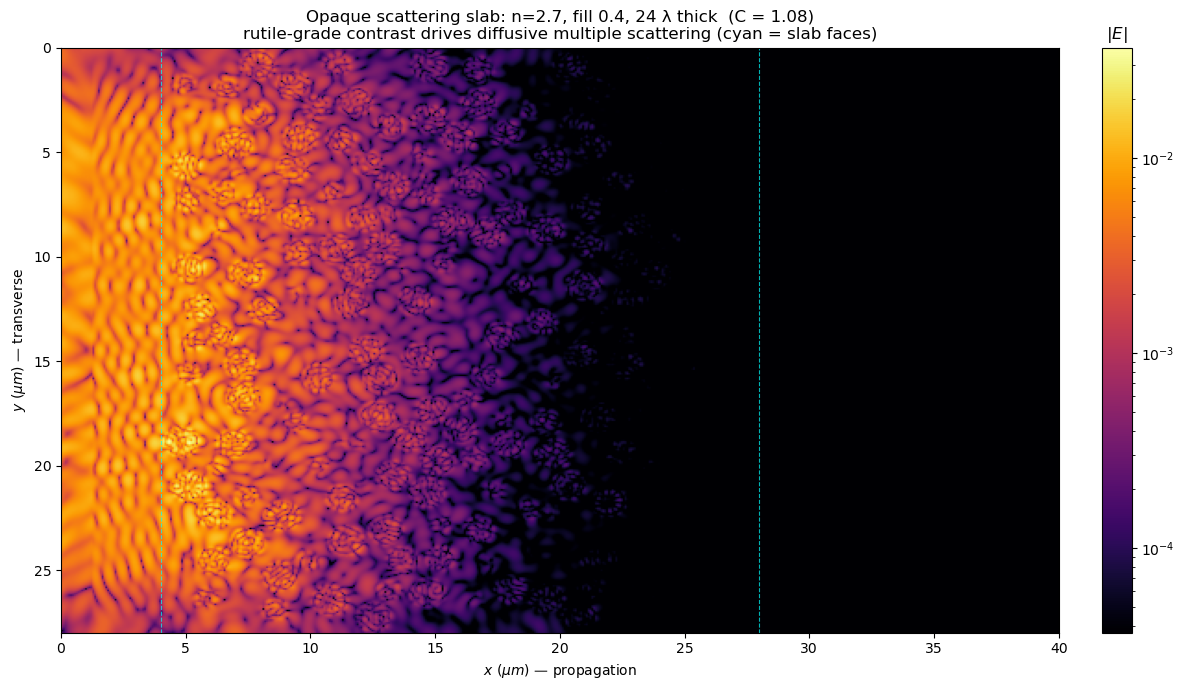

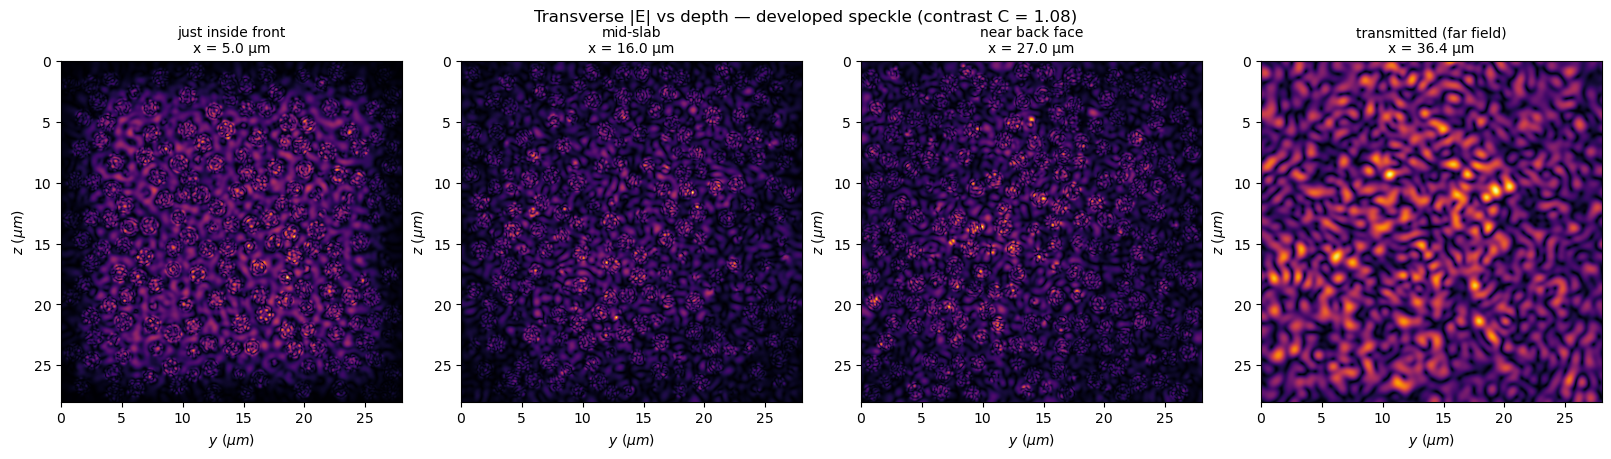

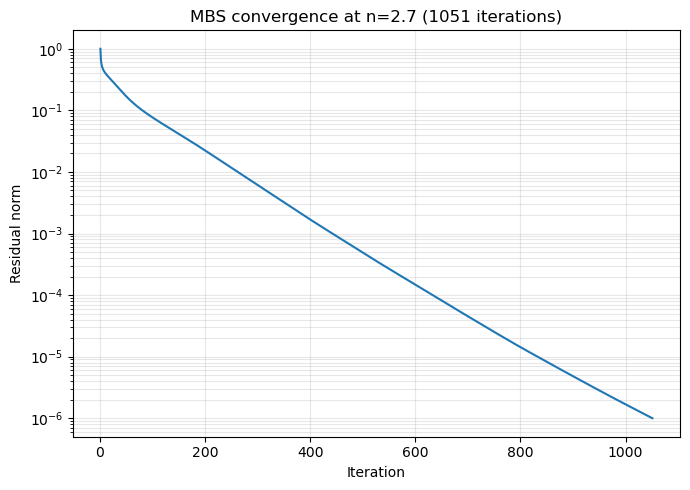

In [5]:
def main():
    report_setup()

    centers = pack_spheres()
    permittivity = build_permittivity(centers)
    source_values, source_position = make_source()

    print("\nRunning simulation...")
    start = time()
    u, iterations, residual_norm = simulate(
        permittivity=permittivity,
        sources=[(source_values, source_position)],
        wavelength=wavelength,
        pixel_size=pixel_size,
        boundary_width=5.0,  # absorbing boundary width, μm (5 λ)
        periodic=(False, False, False),
        full_residuals=True,  # full residual history for the convergence plot
        callback=progress,
    )
    final_res = residual_norm[-1] if np.ndim(residual_norm) else residual_norm
    print(f"Time {time() - start:.1f} s; Iterations {iterations}; Final residual {final_res:.2e}")

    amp = np.abs(np.asarray(u))

    save_volumes(amp, permittivity)

    contrast, grain = speckle_stats(amp)
    print(f"\nFar-field transmitted speckle: contrast C = std(I)/mean(I) = {contrast:.2f} "
          f"(C → 1 for fully developed speckle, as in their Fig. 3a)")
    print(f"Far-field speckle grain size ≈ {grain:.2f} μm = {grain / wavelength:.2f} λ "
          f"(paper: no correlations beyond ~1 λ)")

    plot_xy_slice(amp, contrast)
    plot_transverse(amp, contrast)
    plot_convergence(residual_norm, iterations)
    print(f"Saved output/{NAME}/microspheres_opaque_xy_slice.png, _transverse.png, _convergence.png")
    plt.show()


if __name__ == "__main__":
    main()